# 02 · Logistic Regression

Logistic regression is the classic starting point for yes/no problems. It is also **explainable**, which matters a lot in UK banking (the FCA expects firms to understand their models).

Plan:
1. Show why accuracy fools us (a "do nothing" model)
2. Plain logistic regression
3. Logistic regression with **balanced class weights**
4. Logistic regression with **SMOTE** oversampling
5. Tune `C`, pick a decision **threshold** using a £ cost, and score on the test set **once**

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.utils import *   # load_data, time_split, make_preprocessor, evaluate, ...

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 4.5)

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

df = load_data()
train, val, test = time_split(df)
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]
for name, part in [("train", train), ("validation", val), ("test", test)]:
    print(f"{name:>10}: {len(part):>7,} rows, {part[TARGET].sum():>3} fraud ({part[TARGET].mean():.3%})")

     train: 175,090 rows, 441 fraud (0.252%)
validation:  33,526 rows,  72 fraud (0.215%)
      test:  41,384 rows, 112 fraud (0.271%)


## 1. The accuracy trap

A "model" that predicts *genuine* for everything:

--- Always 'genuine' ---
                accuracy: 0.9979
               precision: 0.0000
   recall (fraud caught): 0.0000
                      f1: 0.0000
     false_negative_rate: 1.0000
           frauds_missed: 72
            false_alarms: 0
                cost_gbp: 9,308.6400


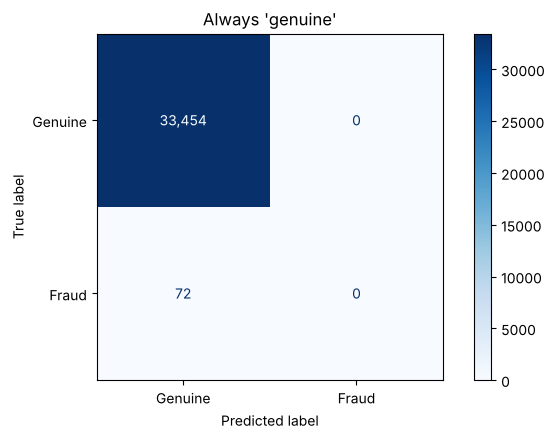

In [3]:
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
_ = evaluate("Always 'genuine'", y_val, dummy.predict(X_val), amounts=val["amount_gbp"])

~99.8% accurate and catches **0 frauds**. This is exactly what happened to the simple neural network in the original project this is based on (it reported 99.8% accuracy but predicted no fraud at all). So from now on, we look at **recall, precision, PR-AUC and £ cost**.

> All tuning below uses the **validation** set. The **test** set is only used at the very end.

## 2. Plain logistic regression

A `Pipeline` bundles preprocessing + model, so scaling is learned from training data only (no **data leakage**).

--- LR - plain (threshold 0.5) ---
                accuracy: 0.9985
               precision: 0.8438
   recall (fraud caught): 0.3750
                      f1: 0.5192
     false_negative_rate: 0.6250
           frauds_missed: 45
            false_alarms: 5
                  pr_auc: 0.5390
                 roc_auc: 0.9477
                cost_gbp: 3,303.8300


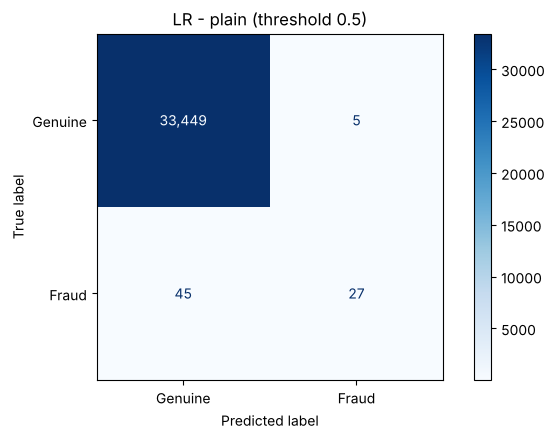

In [4]:
plain = Pipeline([("prep", make_preprocessor()),
                  ("model", LogisticRegression(max_iter=2000))])
plain.fit(X_train, y_train)
p_val = plain.predict_proba(X_val)[:, 1]
_ = evaluate("LR - plain (threshold 0.5)", y_val, (p_val >= 0.5).astype(int), p_val, val["amount_gbp"])

## 3. Balanced class weights

`class_weight="balanced"` tells the model that missing a fraud is ~400× worse than misjudging a genuine payment (because fraud is ~400× rarer). No new data is created.

--- LR - balanced weights (threshold 0.5) ---
                accuracy: 0.9270
               precision: 0.0252
   recall (fraud caught): 0.8750
                      f1: 0.0490
     false_negative_rate: 0.1250
           frauds_missed: 9
            false_alarms: 2,439
                  pr_auc: 0.4567
                 roc_auc: 0.9482
                cost_gbp: 12,562.2300


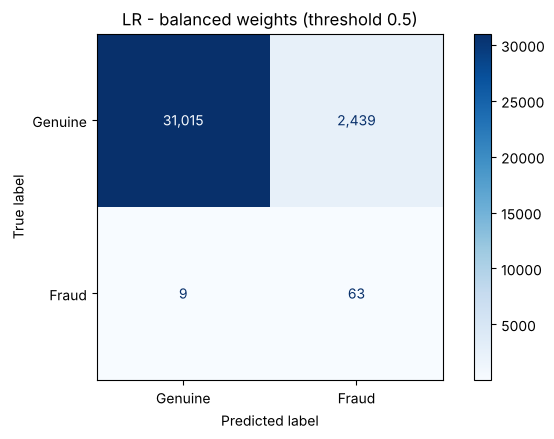

In [5]:
balanced = Pipeline([("prep", make_preprocessor()),
                     ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
balanced.fit(X_train, y_train)
p_val = balanced.predict_proba(X_val)[:, 1]
_ = evaluate("LR - balanced weights (threshold 0.5)", y_val, (p_val >= 0.5).astype(int), p_val, val["amount_gbp"])

Recall jumps (we catch most fraud) but we now raise lots of **false alarms**. That trade-off is controlled by the threshold — see step 5.

## 4. SMOTE oversampling

**SMOTE** creates new, synthetic fraud rows by blending real fraud rows with their neighbours.

⚠️ SMOTE must only touch the **training** data. That's why we use `imblearn`'s Pipeline: it applies SMOTE during `fit` but never during `predict`. (Oversampling *before* splitting would leak copies of test fraud into training and inflate the score.)

--- LR - SMOTE (threshold 0.5) ---
                accuracy: 0.9278
               precision: 0.0255
   recall (fraud caught): 0.8750
                      f1: 0.0495
     false_negative_rate: 0.1250
           frauds_missed: 9
            false_alarms: 2,410
                  pr_auc: 0.4867
                 roc_auc: 0.9457
                cost_gbp: 12,417.2300


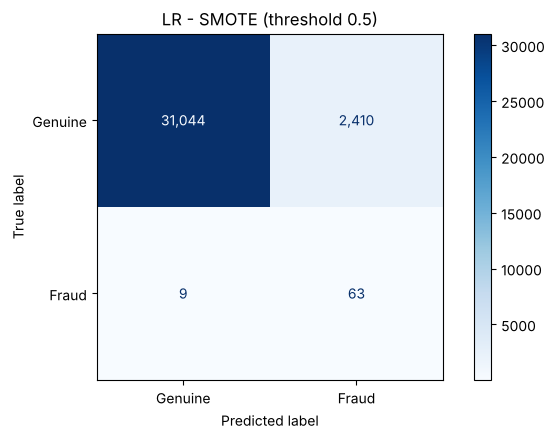

In [6]:
smote = ImbPipeline([("prep", make_preprocessor()),
                     ("smote", SMOTE(random_state=RANDOM_STATE)),
                     ("model", LogisticRegression(max_iter=2000))])
smote.fit(X_train, y_train)
p_val = smote.predict_proba(X_val)[:, 1]
_ = evaluate("LR - SMOTE (threshold 0.5)", y_val, (p_val >= 0.5).astype(int), p_val, val["amount_gbp"])

## 5. Tune C (regularisation) on validation

`C` controls how much the model is allowed to fit the training data. Small C = simpler model. We compare by **PR-AUC** (area under the precision-recall curve), which doesn't depend on a threshold.

In [7]:
rows = []
for C in [0.001, 0.01, 0.1, 1, 10, 100]:
    for weight in [None, "balanced"]:
        m = Pipeline([("prep", make_preprocessor()),
                      ("model", LogisticRegression(C=C, class_weight=weight, max_iter=3000))]).fit(X_train, y_train)
        rows.append({"C": C, "class_weight": weight or "none",
                     "val_pr_auc": average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
tuning = pd.DataFrame(rows).sort_values("val_pr_auc", ascending=False)
tuning.head(8)

,C,class_weight,val_pr_auc
10,100.00,none,0.553383
8,10.00,none,0.550815
4,0.10,none,0.546002
6,1.00,none,0.539015
2,0.01,none,0.493033
11,100.00,balanced,0.456682
7,1.00,balanced,0.456681
9,10.00,balanced,0.456680


In [8]:
best = tuning.iloc[0]
best_C = best["C"]
best_w = None if best["class_weight"] == "none" else "balanced"
print(f"Best: C={best_C}, class_weight={best_w}")
final_lr = Pipeline([("prep", make_preprocessor()),
                     ("model", LogisticRegression(C=best_C, class_weight=best_w, max_iter=3000))]).fit(X_train, y_train)

Best: C=100.0, class_weight=None


### Choosing the threshold with a £ cost

By default a model flags fraud when probability ≥ 0.5. But that number is arbitrary. We pick the threshold that gives the **lowest cost on the validation set**, using simple business assumptions:
- a **missed fraud** costs the full amount (the bank refunds the customer)
- a **false alarm** costs £5 (staff time + customer friction)

In [9]:
p_val = final_lr.predict_proba(X_val)[:, 1]
threshold = best_threshold(y_val, p_val, val["amount_gbp"])
print(f"Chosen threshold: {threshold}")

Chosen threshold: 0.06999999999999999


## 6. Final score on the TEST set (26–30 Sep)

--- Logistic Regression (final) ---
                accuracy: 0.9959
               precision: 0.3623
   recall (fraud caught): 0.6696
                      f1: 0.4702
     false_negative_rate: 0.3304
           frauds_missed: 37
            false_alarms: 132
                  pr_auc: 0.5928
                 roc_auc: 0.9559
                cost_gbp: 3,933.7200


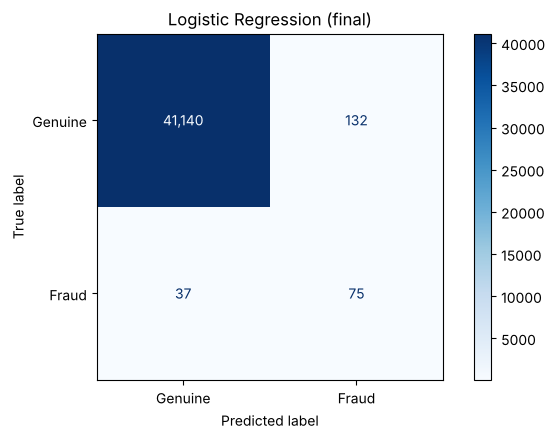

In [10]:
p_test = final_lr.predict_proba(X_test)[:, 1]
lr_results = evaluate("Logistic Regression (final)", y_test, (p_test >= threshold).astype(int), p_test, test["amount_gbp"])

## 7. Explaining the model

Each coefficient says how a feature pushes the fraud odds up (positive) or down (negative). Because numbers were scaled, coefficients are comparable. `exp(coef)` = **odds ratio**.

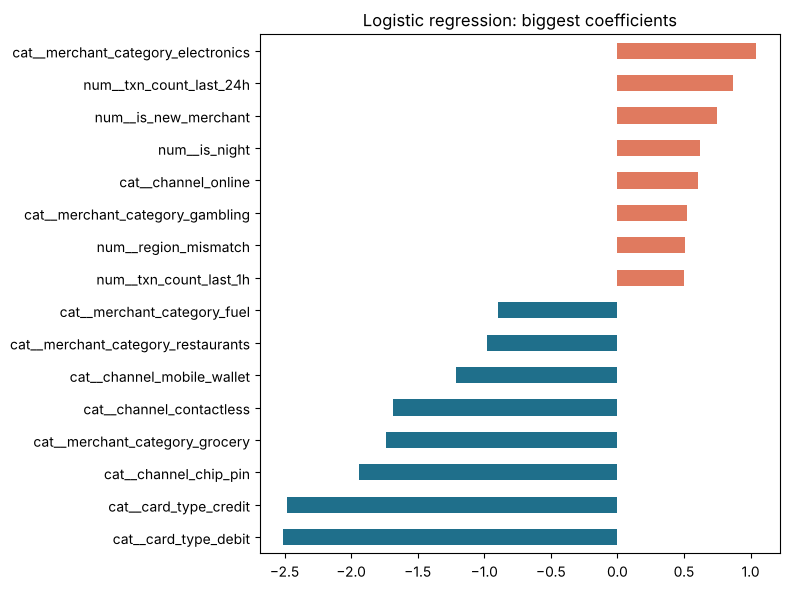

,coef,odds_ratio
cat__merchant_category_electronics,1.043,2.839
num__txn_count_last_24h,0.870,2.387
num__is_new_merchant,0.749,2.115
num__is_night,0.621,1.860
cat__channel_online,0.606,1.832
cat__merchant_category_gambling,0.522,1.685
num__region_mismatch,0.508,1.662
num__txn_count_last_1h,0.502,1.652
num__failed_pin_attempts,0.289,1.335
num__amount_to_avg_ratio,0.276,1.318


In [11]:
names = final_lr.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(final_lr.named_steps["model"].coef_[0], index=names).sort_values()
top = pd.concat([coefs.head(8), coefs.tail(8)])
top.plot.barh(color=["#1f6f8b" if v < 0 else "#e07a5f" for v in top], figsize=(8, 6))
plt.title("Logistic regression: biggest coefficients"); plt.tight_layout()
plt.savefig("../images/lr_coefficients.png", dpi=120, bbox_inches="tight"); plt.show()
pd.DataFrame({"coef": coefs, "odds_ratio": np.exp(coefs)}).sort_values("coef", ascending=False).head(10).round(3)

In [12]:
import json, os
os.makedirs("../results", exist_ok=True)
json.dump({k: (float(v) if not isinstance(v, str) else v) for k, v in lr_results.items()} | {"threshold": threshold},
          open("../results/logistic_regression.json", "w"), indent=2)

## Summary
- Plain LR at 0.5 misses a lot of fraud; class weights or SMOTE raise recall at the cost of more false alarms.
- Choosing the threshold by **£ cost on validation** is more honest than reporting at 0.5.
- The coefficients are easy to explain to a non-technical stakeholder — the big strength of logistic regression.